# Pre-commitment ablation — figures & table

Source: `scripts/evaluation/eval_precommit_ablation.py` (Qwen2.5-Coder-32B, locked 253-spec corpus).
At `prev_end`, `indent`, `var` the residual stream at **every layer** is overwritten with context-free latents
(16 pad tokens + the bare token); `eq` is left intact. Two measures, clean vs ablated:
**frontier implementation** (greedy first line, `judge_implements`) and **GoalScope readout at `eq`**
(122 goal heads, additive_norm α=0.1, L35–46; faithfulness judge vs the clean implementation).

Outputs → `notebooks/Figures/precommit_ablation/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))

In [2]:
import glob, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import figstyle as F
F.set_style()

MODEL = "Qwen2.5-Coder-32B-Instruct"
GROUP = "precommit_ablation"
ABLATED = ["prev_end", "indent", "var"]
LEAF = "ablate=prev_end+indent+var__npad=16__ro=goal122-additive_norm0.1-L35-46__nspec=253__seed=123"
ROOT = os.path.join(env_utils.PROJECT_ROOT, "results", "evaluation", "precommit_ablation", MODEL, LEAF)
S = json.load(open(os.path.join(ROOT, "summary.json")))
R = [json.loads(l) for l in open(os.path.join(ROOT, "records.jsonl"))]
CFG = json.load(open(os.path.join(ROOT, "config.json")))
assert len(R) == S["overall"]["n"] == 253, len(R)
MID = 64 // 2   # Qwen2.5-Coder-32B has 64 layers; bare_*_mid is read at n_layer // 2

# clean = neutral grey, ablated = firebrick (the paper's "ablated" colour in fig:sparsity / app:ablation)
CLEAN_C, ABL_C = "#a6a6a6", "firebrick"
DT = ["int", "str", "list[int]", "list[str]"]
print({k: CFG[k] for k in ["ablate", "n_pad", "n_readout_heads", "steer_layer_range"]})

{'ablate': ['prev_end', 'indent', 'var'], 'n_pad': 16, 'n_readout_heads': 122, 'steer_layer_range': [35, 46]}


In [3]:
# ── sanity: the ablation changed the state, the outputs barely moved ─────────────────
same_gen = sum(r["clean"]["gen"] == r["ablated"]["gen"] for r in R)
same_ro  = sum(r["clean"]["readout_eq"] == r["ablated"]["readout_eq"] for r in R)
flip_v   = sum(r["clean"]["verdict"] != r["ablated"]["verdict"] for r in R)
flip_ro  = sum(r["clean"]["readout_verdict"] != r["ablated"]["readout_verdict"] for r in R)
print(f"generation identical {same_gen}/253 · impl verdict flips {flip_v}/253")
print(f"readout text identical {same_ro}/253 · readout verdict flips {flip_ro}/253")
for p in ABLATED:
    c = [r["bare_cos_mid"][p] for r in R]; n = [r["bare_norm_ratio_mid"][p] for r in R]
    print(f"{p:9s} cos(clean, bare)@L{MID} median {np.median(c):.2f} "
          f"[IQR {np.percentile(c,25):.2f}-{np.percentile(c,75):.2f}] · norm ratio median {np.median(n):.2f}")

generation identical 235/253 · impl verdict flips 0/253
readout text identical 64/253 · readout verdict flips 16/253
prev_end  cos(clean, bare)@L32 median 0.26 [IQR 0.25-0.28] · norm ratio median 0.98
indent    cos(clean, bare)@L32 median 0.31 [IQR 0.30-0.32] · norm ratio median 1.08
var       cos(clean, bare)@L32 median 0.35 [IQR 0.35-0.36] · norm ratio median 1.05


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/precommit_ablation_main.pdf


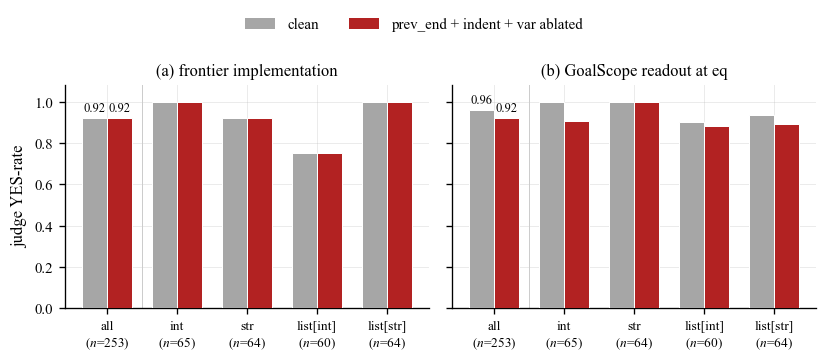

In [4]:
# ── Figure (main): clean vs ablated, implementation and readout, by datatype ──────────
groups = ["all"] + DT
lab = [f"all\n($n$={S['overall']['n']})"] + [f"{d}\n($n$={S['by_datatype'][d]['n']})" for d in DT]
def vals(key):
    return [S["overall"][key]] + [S["by_datatype"][d][key] for d in DT]

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7), sharey=True)
x = np.arange(len(groups)); w = 0.36
for ax, metric, title in [(axes[0], "impl", "(a) frontier implementation"),
                          (axes[1], "readout", "(b) GoalScope readout at eq")]:
    c, a = vals(f"clean_{metric}"), vals(f"ablated_{metric}")
    ax.bar(x - w/2, c, w, color=CLEAN_C, edgecolor="white", linewidth=0.6, zorder=3)
    ax.bar(x + w/2, a, w, color=ABL_C,   edgecolor="white", linewidth=0.6, zorder=3)
    for xi, v in [(-w/2, c[0]), (w/2, a[0])]:          # direct labels on the pooled group only
        ax.text(xi, v + .015, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5)
    ax.axvline(0.5, color="#cccccc", lw=0.6, zorder=1)
    ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylim(0, 1.08)
axes[0].set_ylabel("judge YES-rate")
handles = [Patch(facecolor=CLEAN_C, label="clean"),
           Patch(facecolor=ABL_C, label="prev_end + indent + var ablated")]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.tight_layout()
print("saved", F.save_fig(fig, GROUP, "precommit_ablation_main")); plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/precommit_ablation_diagnostics.pdf


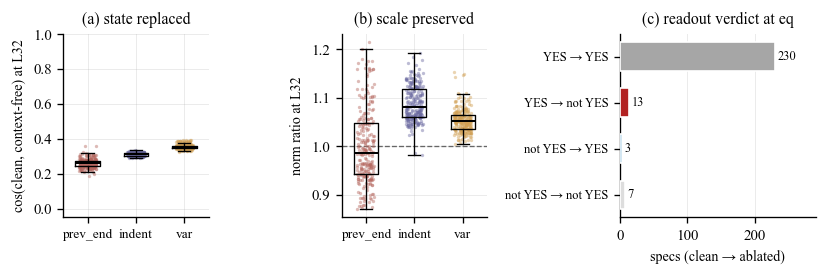

counts: {'YES → YES': 230, 'YES → not YES': 13, 'not YES → YES': 3, 'not YES → not YES': 7}


In [5]:
# ── Figure (appendix): the ablation is strong; the readout rarely loses content ────────
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.4), gridspec_kw=dict(width_ratios=[1, 1, 1.35]))
rng = np.random.default_rng(0)
for ax, key, ylab, ref in [(axes[0], "bare_cos_mid", f"cos(clean, context-free) at L{MID}", None),
                           (axes[1], "bare_norm_ratio_mid", f"norm ratio at L{MID}", 1.0)]:
    for i, p in enumerate(ABLATED):
        v = np.array([r[key][p] for r in R])
        ax.scatter(i + rng.uniform(-.18, .18, len(v)), v, s=4, color=F.PIVOT_COLOR[p], alpha=.45,
                   linewidths=0, zorder=2)
        ax.boxplot(v, positions=[i], widths=.5, showfliers=False, zorder=3,
                   medianprops=dict(color="black", lw=1.2), boxprops=dict(lw=.8),
                   whiskerprops=dict(lw=.8), capprops=dict(lw=.8))
    if ref is not None:
        ax.axhline(ref, ls="--", lw=.8, color="#666", zorder=1)
    ax.set_xticks(range(len(ABLATED))); ax.set_xticklabels(ABLATED, fontsize=8)
    ax.set_ylabel(ylab, fontsize=8.5)
axes[0].set_ylim(-0.05, 1.0); axes[0].set_title("(a) state replaced", fontsize=9.5)
axes[1].set_title("(b) scale preserved", fontsize=9.5)

# (c) readout verdict under ablation, split by the clean verdict
yes = lambda v: v == "YES"
cats = [("YES → YES",         lambda r: yes(r["clean"]["readout_verdict"]) and yes(r["ablated"]["readout_verdict"])),
        ("YES → not YES",     lambda r: yes(r["clean"]["readout_verdict"]) and not yes(r["ablated"]["readout_verdict"])),
        ("not YES → YES",     lambda r: not yes(r["clean"]["readout_verdict"]) and yes(r["ablated"]["readout_verdict"])),
        ("not YES → not YES", lambda r: not yes(r["clean"]["readout_verdict"]) and not yes(r["ablated"]["readout_verdict"]))]
cnt = [sum(f(r) for r in R) for _, f in cats]
ax = axes[2]; y = np.arange(len(cats))[::-1]
ax.barh(y, cnt, color=[CLEAN_C, ABL_C, "#0072B2", "#dddddd"], edgecolor="white", height=.62, zorder=3)
for yi, c in zip(y, cnt):
    ax.text(c + 4, yi, str(c), va="center", fontsize=7.5)
ax.set_yticks(y); ax.set_yticklabels([c for c, _ in cats], fontsize=7.5)
ax.set_xlim(0, 290); ax.set_xlabel("specs (clean → ablated)", fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_title("(c) readout verdict at eq", fontsize=9.5)
fig.tight_layout()
print("saved", F.save_fig(fig, GROUP, "precommit_ablation_diagnostics")); plt.show()
print("counts:", dict(zip([c for c, _ in cats], cnt)))

In [6]:
# ── LaTeX table: clean / ablated rates by datatype and frontier depth ──────────────────
def row(name, d):
    return (f"{name} & {d['n']} & {d['clean_impl']:.3f} & {d['ablated_impl']:.3f} & "
            f"{d['clean_readout']:.3f} & {d['ablated_readout']:.3f} \\\\")
lines = [r"\begin{tabular}{l r cc cc}", r"\toprule",
         r" & & \multicolumn{2}{c}{implementation} & \multicolumn{2}{c}{readout at \texttt{eq}} \\",
         r"\cmidrule(lr){3-4}\cmidrule(lr){5-6}",
         r"subset & $n$ & clean & ablated & clean & ablated \\", r"\midrule",
         row(r"\textbf{all}", S["overall"]), r"\midrule"]
lines += [row(r"\texttt{" + d + "}", S["by_datatype"][d]) for d in DT]
lines += [r"\midrule"] + [row(f"$j={j}$", S["by_frontier_j"][j]) for j in sorted(S["by_frontier_j"])]
lines += [r"\bottomrule", r"\end{tabular}"]
tex = "\n".join(lines)
print("wrote", F.save_table(tex, GROUP, "precommit_ablation_table")); print(tex)

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/precommit_ablation_table.tex
\begin{tabular}{l r cc cc}
\toprule
 & & \multicolumn{2}{c}{implementation} & \multicolumn{2}{c}{readout at \texttt{eq}} \\
\cmidrule(lr){3-4}\cmidrule(lr){5-6}
subset & $n$ & clean & ablated & clean & ablated \\
\midrule
\textbf{all} & 253 & 0.921 & 0.921 & 0.961 & 0.921 \\
\midrule
\texttt{int} & 65 & 1.000 & 1.000 & 1.000 & 0.908 \\
\texttt{str} & 64 & 0.922 & 0.922 & 1.000 & 1.000 \\
\texttt{list[int]} & 60 & 0.750 & 0.750 & 0.900 & 0.883 \\
\texttt{list[str]} & 64 & 1.000 & 1.000 & 0.938 & 0.891 \\
\midrule
$j=1$ & 151 & 0.927 & 0.927 & 0.954 & 0.934 \\
$j=2$ & 73 & 0.904 & 0.904 & 0.959 & 0.890 \\
$j=3$ & 29 & 0.931 & 0.931 & 1.000 & 0.931 \\
\bottomrule
\end{tabular}


## Pre-commitment swap (replaces the context-free ablation in Appendix J)

Source: `scripts/diff/precommit_swap_eval.py` (`src/diff/precommit_swap.py`; report
`agent_reports/claude/analysis/precommitment-swap-report.md`). `p_dst: a'b'd -> d` ← `p_src: a'b'c -> c`: every layer's output
residual over `<|im_end|> … {var}` is replaced with SRC's (eq pivot ` =` left clean). Two configs:
**progress only** (`front-off`) and **src frontier + progress** (`front-on`, also SRC's c description → DST's d description, the
positive control). Py→py, 4 datatypes × 32 = 128 per config. Causal-shift = patched implements c (BOTH is a miss);
readout-shift = GoalScope at ` =` (goal-250) shifts to c, over all instances. Output → `precommit_ablation/precommit_swap_bars`.

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/precommit_swap_bars.pdf
   progress only              n=128  causal-shift 0.062  readout-shift 0.062
   src frontier + progress    n=128  causal-shift 0.984  readout-shift 1.000


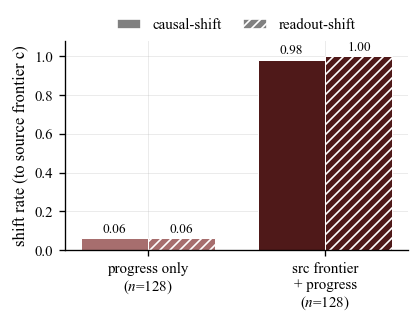

In [7]:
# ── Figure: pre-commitment swap — aggregated causal / readout shift, progress only vs src frontier + progress ──
SWAP_ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "diff", MODEL, "precommit_swap")
SWAP_ARMS = {"progress only": "I2-src__front-off__layers-all__ro-goal_250",
             "src frontier\n+ progress": "I2-src__front-on__layers-all__ro-goal_250"}
SWAP_COLOR = {"progress only": "#a76e6e", "src frontier\n+ progress": "#4f1919"}   # matte reds, one per group

def swap_rates(arm):
    # pooled over every instance of the arm (= mean of the per-datatype cells: n = 32 each)
    recs = [r for f in sorted(glob.glob(os.path.join(SWAP_ROOT, arm, "*", "results.json"))) for r in json.load(open(f))]
    causal = np.mean([r["causal"]["triggered"] for r in recs])
    readout = np.mean([r["readout"]["shifted"] for r in recs])
    return causal, readout, len(recs)

SWAP = {g: swap_rates(a) for g, a in SWAP_ARMS.items()}
fig, ax = plt.subplots(figsize=(3.6, 2.8))
x = np.arange(len(SWAP)); w = 0.38
for i, (g, (cz, rd, _)) in enumerate(SWAP.items()):
    ax.bar(x[i] - w/2, cz, w, **F.metric_kw("causal", SWAP_COLOR[g]))
    ax.bar(x[i] + w/2, rd, w, **F.metric_kw("readout", SWAP_COLOR[g]))
for cont in ax.containers:   # value on top of every bar
    ax.bar_label(cont, fmt="%.2f", padding=1.5, fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n($n$={v[2]})" for g, v in SWAP.items()])
ax.set_ylim(0, 1.08); ax.set_ylabel("shift rate (to source frontier c)")
F.legend_top(ax, handles=F.metric_legend_handles(labels=("causal-shift", "readout-shift")),
             labels=["causal-shift", "readout-shift"])
fig.tight_layout()
print("saved", F.save_fig(fig, GROUP, "precommit_swap_bars"))
for g, (c, r, n) in SWAP.items():
    print(f"   {g.replace(chr(10), ' '):<26} n={n}  causal-shift {c:.3f}  readout-shift {r:.3f}")
plt.show()

## Task-span vs code-progress span (replaces the pre-commitment swap in Appendix J)

Source: `scripts/diff/task_vs_progress_eval.py` (`src/diff/task_vs_progress.py`; report
`agent_reports/claude/analysis/task-vs-progress-report.md`). Python → Python, 4 datatypes × 32 = 128 per cell, causal-shift
only (oracle `claude-sonnet-4-6`, BOTH = miss). Each 2 × 2 grid fixes the intervention: rows = where the **task span**
(the task list + its closing `\n`) comes from, columns = where the **code-progress span** (`<|im_end|> … {var}`) comes from.
The top-left corner is the clean DST run.

- `tvp_residual_grid` — residual transfer (every layer + input embeddings; the span not transferred is pinned to clean DST). Fig 27 right panel.
- `tvp_kv_grids` — pivot-onwards KV transfer, 250 goal heads (top row) / all heads (bottom row) × V-boost 1, 2, 4.
- `tvp_residual_table` — residual transfer by datatype.

In [8]:
# ── task-vs-progress: load the per-datatype summaries (the batch driver's <cache dir>.summary.json) ──
from matplotlib.colors import LinearSegmentedColormap
TVP_ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_caches", "task_vs_progress", MODEL)
TVP_DT = {"int": "int", "str": "str", "list[int]": "list_int", "list[str]": "list_str"}
TVP = {d: json.load(open(os.path.join(TVP_ROOT, f"{s}__python-python__seed1123__mx64__ro0__task+gap.summary.json")))
       for d, s in TVP_DT.items()}
assert all(v["n"] == 32 for s in TVP.values() for v in s.values()), "every config must have all 32 instances"

def tvp_name(method, heads, span, v):   # = src.diff.task_vs_progress.cfg_name
    return "clean DST (no-op)" if method == "none" else f"{method}{'·' + heads if heads else ''} · {span} · V×{v:g}"

def tvp_rate(name, dts=DT):   # pooled causal-shift (equal n per datatype -> mean of the cells)
    return float(np.mean([TVP[d][name]["causal_shift"] for d in dts]))

def tvp_grid(method, heads=None, v=1.0):
    # [[task DST · prog DST, task DST · prog SRC], [task SRC · prog DST, task SRC · prog SRC]]
    return np.array([[tvp_rate(tvp_name("none", None, "none", 1.0)), tvp_rate(tvp_name(method, heads, "progress", v))],
                     [tvp_rate(tvp_name(method, heads, "task", v)),  tvp_rate(tvp_name(method, heads, "task+progress", v))]])

# sequential single hue (the model colour), light -> dark; value labels on every cell
TVP_CMAP = LinearSegmentedColormap.from_list("tvp", ["#f3f7fb", F.MODEL_COLOR[MODEL]])          # KV transfer
TVP_CMAP_RES = LinearSegmentedColormap.from_list("tvp_res", ["#fbf3f2", "firebrick"])   # residual transfer

def draw_tvp_grid(ax, M, title=None, ticklabels=True, fontsize=11, cmap=None):
    ax.imshow(M, cmap=cmap or TVP_CMAP, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=fontsize,
                    color="white" if M[i, j] > 0.55 else "#1a1a1a")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    if ticklabels:
        ax.set_xticklabels(["DST", "SRC"]); ax.set_yticklabels(["DST", "SRC"])
        ax.set_xlabel("code-progress span from"); ax.set_ylabel("task span from")
    else:
        ax.set_xticklabels([]); ax.set_yticklabels([])
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks([0.5], minor=True); ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="white", linewidth=3, alpha=1); ax.grid(which="major", visible=False)
    if title:
        ax.set_title(title, fontsize=10)

for m, h, v in [("residual", None, 1.0)] + [("kv", h, v) for h in ("goal250", "all") for v in (1.0, 2.0, 4.0)]:
    print(f"{m:8s} {str(h):8s} V×{v:g}\n", tvp_grid(m, h, v).round(2))

residual None     V×1
 [[0.   0.06]
 [0.89 0.98]]
kv       goal250  V×1
 [[0.   0.  ]
 [0.77 0.98]]
kv       goal250  V×2
 [[0.   0.04]
 [0.93 0.98]]
kv       goal250  V×4
 [[0.   0.26]
 [0.97 0.98]]
kv       all      V×1
 [[0.   0.06]
 [0.89 0.98]]
kv       all      V×2
 [[0.   0.16]
 [0.98 0.98]]
kv       all      V×4
 [[0.   0.38]
 [0.98 0.99]]


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/tvp_residual_grid.pdf


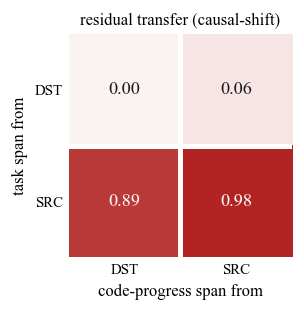

In [9]:
# ── Figure 27 (right panel): residual transfer, the 2 × 2 grid ──
fig, ax = plt.subplots(figsize=(2.9, 2.7))
draw_tvp_grid(ax, tvp_grid("residual"), title="residual transfer (causal-shift)", cmap=TVP_CMAP_RES)
fig.tight_layout()
print("saved", F.save_fig(fig, GROUP, "tvp_residual_grid")); plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/tvp_kv_grids.pdf


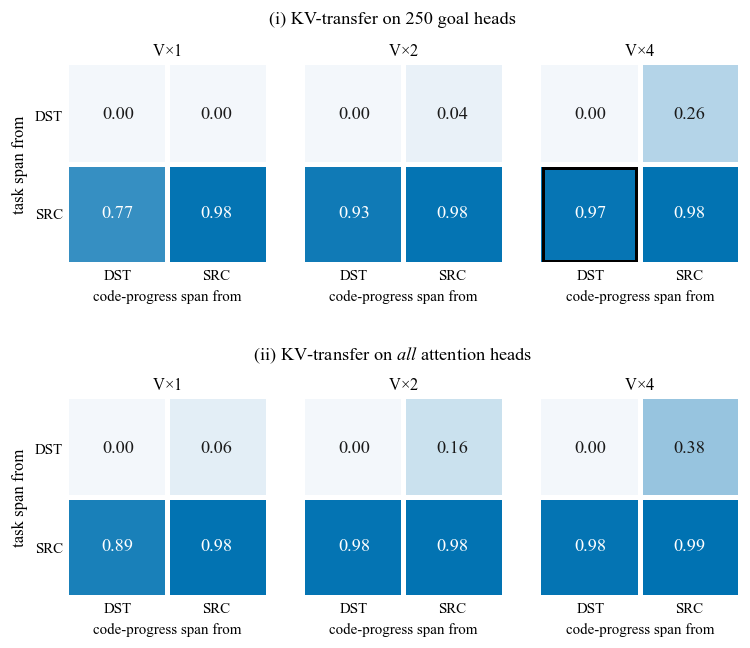

In [10]:
# ── KV transfer (pivot-onwards): (a) 250 goal heads / (b) all attention heads × V-boost 1, 2, 4 ──
ROWS = [("goal250", "(i) KV-transfer on 250 goal heads"), ("all", "(ii) KV-transfer on $all$ attention heads")]
VS = [1.0, 2.0, 4.0]
DEFAULT_KV = ("goal250", 4.0)   # boxed cell: the configuration reported in App I.1 (Fig 22 / Table 7)
fig = plt.figure(figsize=(7.2, 5.4))
subfigs = fig.subfigures(2, 1, hspace=0.06)
for sf, (h, rlab) in zip(subfigs, ROWS):
    sf.suptitle(rlab, fontsize=11)
    axes = sf.subplots(1, 3)
    for c, (ax, v) in enumerate(zip(axes, VS)):
        draw_tvp_grid(ax, tvp_grid("kv", h, v), title=f"V$\\times${v:g}", ticklabels=False)
        ax.set_xticklabels(["DST", "SRC"]); ax.set_yticklabels(["DST", "SRC"] if c == 0 else [])
        ax.set_xlabel("code-progress span from", fontsize=9)
        if c == 0: ax.set_ylabel("task span from")
        if (h, v) == DEFAULT_KV:
            BOX_AX = ax
fig.canvas.draw()
pt = BOX_AX.get_window_extent().width / 2 / (fig.dpi / 72)   # points per data unit (2 cells across)
lw, gap = 1.8, 3 / 2                                          # border width; half the white cell gap (grid linewidth 3)
o, i = (lw / 2) / pt, (gap + lw / 2) / pt                     # inset at the outer image edge / at the cell gap
# boxed cell = row 1 (task from SRC), col 0 (progress from DST): x in [-0.5, 0.5], y in [0.5, 1.5]
BOX_AX.add_patch(plt.Rectangle((-0.5 + o, 0.5 + i), 1 - o - i, 1 - o - i, fill=False, edgecolor="black",
                               linewidth=lw, joinstyle="miter", zorder=5))
print("saved", F.save_fig(fig, GROUP, "tvp_kv_grids")); plt.show()

In [11]:
# ── LaTeX table: residual transfer by datatype (causal-shift; clean DST = 0 everywhere) ──
def tvp_row(label, dts):
    return (f"{label} & {32 * len(dts)} & " + " & ".join(f"{tvp_rate(tvp_name('residual', None, s, 1.0), dts):.2f}"
                                                         for s in ("task", "progress", "task+progress")) + r" \\")
lines = [r"\begin{tabular}{l r ccc}", r"\toprule",
         r" & & \multicolumn{3}{c}{span(s) from the source run} \\", r"\cmidrule(lr){3-5}",
         r"Subset & $n$ & task only & code progress only & task + code progress \\", r"\midrule",
         tvp_row(r"\textbf{all}", DT), r"\midrule"] + [tvp_row(rf"\texttt{{{d}}}", [d]) for d in DT] + [r"\bottomrule", r"\end{tabular}"]
body = "\n".join(lines)
print(body); print("saved", F.save_table(body, GROUP, "tvp_residual_table"))

\begin{tabular}{l r ccc}
\toprule
 & & \multicolumn{3}{c}{span(s) from the source run} \\
\cmidrule(lr){3-5}
Subset & $n$ & task only & code progress only & task + code progress \\
\midrule
\textbf{all} & 128 & 0.89 & 0.06 & 0.98 \\
\midrule
\texttt{int} & 32 & 0.78 & 0.06 & 0.97 \\
\texttt{str} & 32 & 0.91 & 0.00 & 1.00 \\
\texttt{list[int]} & 32 & 0.94 & 0.16 & 0.97 \\
\texttt{list[str]} & 32 & 0.94 & 0.03 & 1.00 \\
\bottomrule
\end{tabular}
saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/tvp_residual_table.tex
